# AI Problem Formulation — Visual Examples

**Execution status:** this notebook is executed by its builder; actual cell outputs are saved. Examples are synthetic and perform no network operations.

## 1. Introduction and learning objectives

Problem formulation turns a vague request into a task with a goal, observations, candidate actions, hard constraints, costs, and evaluation. You will translate an everyday request into a simple specification, rank options, add a safety boundary, and visualize how cost assumptions affect choices.

**Prerequisites:** Python basics and the course's AI introduction. **Objectives:** distinguish constraints from preferences; calculate a weighted score; identify when an option must be excluded; explain the chart and its units.

## 2. Beginner explanation

“Help with a slow network” could mean diagnose latency, find packet loss, or recommend a configuration change. We first define the intended output. In this lab the system only ranks evidence for an operator; it never executes commands.

In [1]:
import importlib.util
import sys
from pathlib import Path
import matplotlib

implementation_path = Path("07_Artificial_Intelligence_Fundamentals/02_AI_Problem_Formulation_Visual_Examples/05_problem_formulation.py")
spec = importlib.util.spec_from_file_location("problem_formulation", implementation_path)
if spec is None or spec.loader is None:
    raise RuntimeError(f"Cannot load reusable implementation: {implementation_path}")
implementation = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = implementation
spec.loader.exec_module(implementation)
task, sample_actions = implementation.build_network_example()
print(f"Python {sys.version.split()[0]} | Matplotlib {matplotlib.__version__}")
print("Reusable implementation loaded; no device connection created.")

Python 3.13.14 | Matplotlib 3.10.8
Reusable implementation loaded; no device connection created.


## 3. Mathematical background

For a candidate \(a\), this lesson uses \(J(a)=\alpha t(a)+\beta r(a)-\gamma i(a)\). Here \(t\) is estimated time units, \(r\) normalized risk (0–1), \(i\) illustrative information value (0–1), and the nonnegative coefficients express preference weights. A lower score is preferred only among candidates allowed by hard constraints.

Worked example: counter inspection with \(t=2,r=0,i=0.6\), weights \((1,10,2)\), has \(J=2+0-1.2=0.8\). This score is a teaching calculation, not a measured probability or operational risk estimate.

## 4. Example 1 — Absolute beginner

A goal says what we want; a constraint states what is allowed. The following plain dictionary makes both visible. Each variable is a text description, not a command.

In [2]:
task_card = {
    "goal": "show the operator useful evidence",
    "observation": "synthetic latency is elevated",
    "allowed": "read-only inspection",
    "prohibited": "device configuration change",
}
print(task_card["goal"])
print("Hard constraint:", task_card["prohibited"])

show the operator useful evidence
Hard constraint: device configuration change


**Walkthrough:** `task_card` is a dictionary mapping field names to descriptions. The two `print` calls retrieve values using keys. The output repeats the goal and prohibition because those strings were assigned above. This is useful because it makes scope explicit before selecting a model.

## 5. Example 2 — Beginner practical formulation

A latency conversion has a measurable goal and input constraint. It is ordinary deterministic software; AI is unnecessary for this exact task.

In [3]:
def latency_ms(seconds: float) -> float:
    if seconds < 0:
        raise ValueError("latency seconds must be non-negative")
    return seconds * 1000

print(f"Latency: {latency_ms(0.125):.1f} ms")

Latency: 125.0 ms


The function accepts seconds, checks a domain constraint, converts by multiplying by 1000, and returns milliseconds. The formatted output displays one decimal place. If the input is negative, the function rejects it instead of reporting an invalid latency.

## 6. Example 3 — Intermediate candidate ranking

The reusable module stores candidate descriptions, hard constraints, and soft preferences. It only ranks options; it has no device API.

In [4]:
print("Goal:", task.goal)
for action, score in task.rank_candidates(sample_actions):
    print(f"{action.name}: cost={score:.2f}; changes_state={action.changes_state}")
print("A state-changing candidate is filtered without approval.")

Goal: Rank useful diagnostic evidence for an operator without changing devices.
collect_read_only_counters: cost=0.80; changes_state=False
inspect_routing_neighbor: cost=1.20; changes_state=False
A state-changing candidate is filtered without approval.


The counter inspection scores \(2-2(0.6)=0.8\); routing inspection scores \(3-2(0.9)=1.2\). The interface reset is excluded by the no-write constraint before ranking. Candidate scores depend on the illustrative weights and estimates.

## 7. Example 4 — Advanced weight sensitivity and approval

Preferences may vary, but hard constraints remain distinct. The first ranking changes the risk weight for permitted actions. An explicit approval flag shows a boundary in this toy policy; it is not production authentication.

In [5]:
for risk_weight in (2.0, 10.0, 30.0):
    varied = implementation.TaskFormulation(
        goal=task.goal,
        prohibited_actions=task.prohibited_actions,
        risk_weight=risk_weight,
    )
    names = [action.name for action, _ in varied.rank_candidates(sample_actions)]
    print(f"risk_weight={risk_weight:g}: {names}")

approved_view = task.rank_candidates(sample_actions, human_approved=True)
print("With explicit demo approval, descriptions considered:", [a.name for a, _ in approved_view])
print("No action is executed.")

risk_weight=2: ['collect_read_only_counters', 'inspect_routing_neighbor']
risk_weight=10: ['collect_read_only_counters', 'inspect_routing_neighbor']
risk_weight=30: ['collect_read_only_counters', 'inspect_routing_neighbor']
With explicit demo approval, descriptions considered: ['collect_read_only_counters', 'inspect_routing_neighbor', 'reset_interface']
No action is executed.


Changing soft weights can reorder permitted options. The reset remains excluded unless the caller explicitly sets the demonstration approval argument. Real systems must enforce identity, scope, policy, audit, and change approval independently of an AI model.

## 8. Example 5 — Real-world read-only network scenario

The following synthetic fields describe a possible troubleshooting snapshot. The task is to gather evidence for a human, not to assert a cause or alter routing.

In [6]:
snapshot = {
    "site": "synthetic-site-01",
    "latency_ms": 118.0,
    "packet_loss_pct": 2.0,
    "bgp_state": "Established",
    "data_is_synthetic": True,
}
evidence = [key for key in ("latency_ms", "packet_loss_pct", "bgp_state") if key in snapshot]
print("Evidence fields:", evidence)
print("Observation:", snapshot)
print("Recommendation scope: inspect evidence; do not change device state.")

Evidence fields: ['latency_ms', 'packet_loss_pct', 'bgp_state']
Observation: {'site': 'synthetic-site-01', 'latency_ms': 118.0, 'packet_loss_pct': 2.0, 'bgp_state': 'Established', 'data_is_synthetic': True}
Recommendation scope: inspect evidence; do not change device state.


The list comprehension collects available evidence keys. The BGP state and latency are separate observations; an established neighbor alone does not prove end-to-end service health. Real use requires timestamps, units, provenance, missing-data handling, and domain review.

## 9. Visualization — candidate time, risk, and information

Each point is one synthetic candidate. **X-axis:** estimated investigation time (arbitrary units). **Y-axis:** normalized illustrative risk from 0 to 1. Bubble area encodes illustrative information value, not statistical confidence. The state-changing reset is marked separately and is prohibited by this lab's hard constraint.

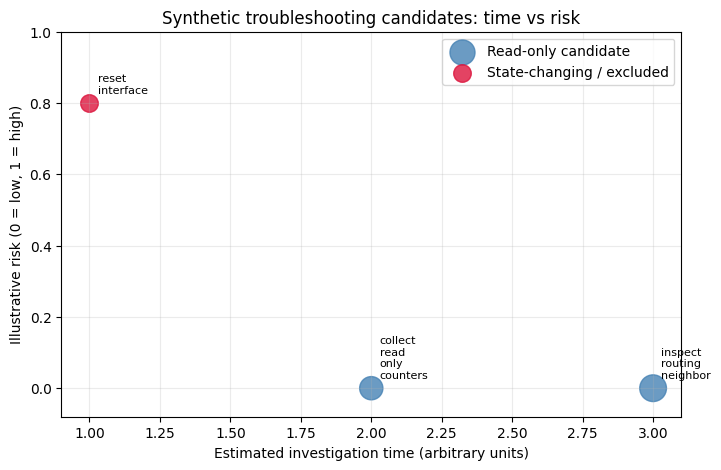

In [7]:
import matplotlib.pyplot as plt

permitted, excluded = [], []
for candidate in sample_actions:
    (excluded if candidate.changes_state else permitted).append(candidate)

fig, ax = plt.subplots(figsize=(8, 5))
for group, color, label in ((permitted, "steelblue", "Read-only candidate"),
                            (excluded, "crimson", "State-changing / excluded")):
    if group:
        ax.scatter(
            [item.time_units for item in group],
            [item.risk for item in group],
            s=[100 + 300 * item.information_value for item in group],
            color=color,
            label=label,
            alpha=0.8,
        )
        for item in group:
            ax.annotate(item.name.replace("_", "\n"),
                        (item.time_units, item.risk), xytext=(6, 7),
                        textcoords="offset points", fontsize=8)
ax.set(title="Synthetic troubleshooting candidates: time vs risk",
       xlabel="Estimated investigation time (arbitrary units)",
       ylabel="Illustrative risk (0 = low, 1 = high)")
ax.set_ylim(-0.08, 1.0)
ax.legend()
ax.grid(alpha=0.25)
plt.show()

**Interpretation:** read-only candidates appear at risk 0; the reset is at risk 0.8 and marked excluded. Larger bubbles correspond to higher assumed information value. If time/risk estimates or inputs change, positions and preferred ranking change. The chart explains assumptions; it is not operational telemetry or empirical evidence.

## 10. Debugging and common mistakes

The invalid example is caught and printed. A hard constraint should not be replaced by a large score penalty, and malformed measurements must not silently pass.

In [8]:
try:
    latency_ms(-0.5)
except ValueError as error:
    print(f"Rejected invalid measurement: {error}")

try:
    invalid_action = implementation.CandidateAction("bad", 1.0, 1.5, 0.2)
    invalid_action.validate()
except ValueError as error:
    print(f"Rejected invalid risk: {error}")

Rejected invalid measurement: latency seconds must be non-negative
Rejected invalid risk: risk must be between 0 and 1


## 11. Practice and experiment

Change `risk_weight` and rerun the advanced cell. Add a new read-only candidate with an estimated duration and information value, then describe why those estimates are uncertain. Attempt the separate [exercise notebook](03_AI_Problem_Formulation_Exercises.ipynb) before opening its solutions.

## 12. Summary and next topic

A good formulation states the goal, observations, candidate outputs, hard constraints, soft costs, and evaluation. Ranking never grants execution authority. Next: search and planning over explicit states and action sequences.